In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

In [2]:
for i in range(2):
    for j in range(2):
        print(f'[{i},{j}]')

[0,0]
[0,1]
[1,0]
[1,1]


In [114]:
def test_model(model, dataset):
    filtered_data = []
    TP = 0
    FP = 0
    TN = 0
    FN = 0
    for i, (images, label) in enumerate(dataset, 0):
        output = model(images)
        prediction = output.numpy()
        for i in range(len(prediction)):
            if prediction[i][0] > 0.4:
                if label[i]== 1:
                    TP += 1
                else: FP += 1
                filtered_data.append(images[i])
                # print(prediction[i], label[i])
            else:
                if label[i]== 1:
                    FN += 1
                else: TN += 1

    f1 = (2*TP)/(2*TP+FP+FN)
    return filtered_data, TP, FP, TN, FN, f1

In [115]:
def test_model2(model, dataset):
    y_pred = model.predict(dataset, verbose=0)
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    array = confusion_matrix(y_true, y_pred.round())
    return array

In [116]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_64_test/',
    labels='inferred',
    label_mode='binary',
    batch_size=32,
    image_size=(64,64),
    seed=42,
    shuffle=False
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
test_ds = test_ds.map(process)

model64 = keras.models.load_model("./trained_models/model64_test/")

Found 1236 files belonging to 2 classes.


In [117]:
# def test_model(model, dataset):
#     filtered_data = []
#     TP = 0
#     FP = 0
#     TN = 0
#     FN = 0
#     for i, (images, label) in enumerate(dataset, 0):
#         output = model(images)
#         prediction = output.numpy()
#         for i in range(len(prediction)):
#             if prediction[i][0] > 0.4:
#                 if label[i]== 1:
#                     TP += 1
#                 else: FP += 1
#                 filtered_data.append(images[i])
#                 # print(prediction[i], label[i])
#             else:
#                 if label[i]== 1:
#                     FN += 1
#                 else: TN += 1

#     f1 = (2*TP)/(2*TP+FP+FN)
#     return filtered_data, TP, FP, TN, FN, f1

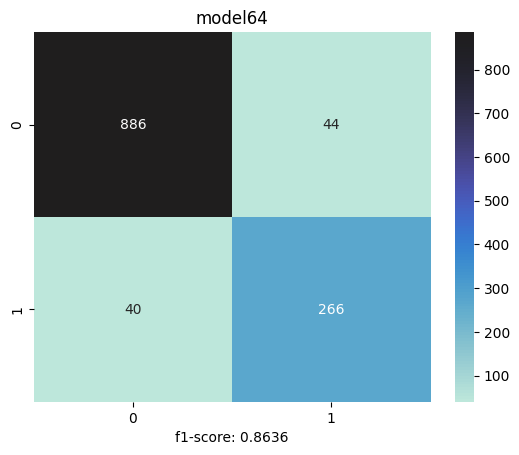

In [118]:
# saved_model64 = keras.models.load_model("./trained_models/model64_test/")
array = test_model2(model64, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

# df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model64')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.show()

Found 1082 files belonging to 2 classes.


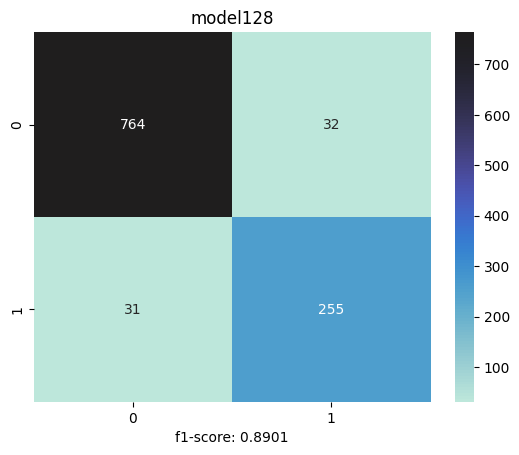

In [119]:
saved_model128 = keras.models.load_model("./trained_models/model128_test/")
test_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_128_test/',
    labels='inferred',
    label_mode='binary',
    batch_size=16,
    image_size=(128,128),
    seed=42,
    shuffle=False,
)
test_ds = test_ds.map(process)

array = test_model2(saved_model128, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model128')
plt.xlabel(f'f1-score: {round(f1,4)}')

plt.show()

Found 4492 files belonging to 2 classes.


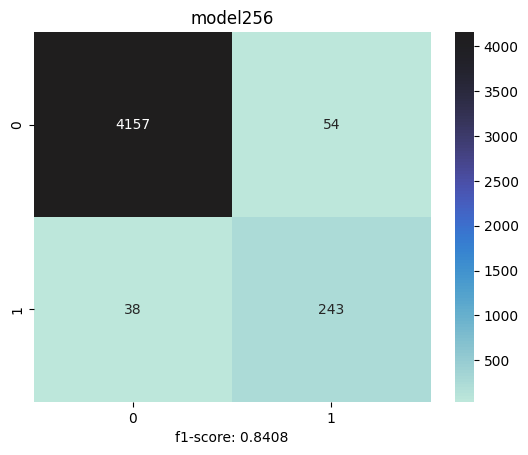

In [120]:
saved_model256 = keras.models.load_model("./trained_models/model256_test/")
test_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_256_test/',
    labels='inferred',
    label_mode='binary',
    batch_size=8,
    image_size=(256,256),
    seed=42,
    shuffle=False
)
test_ds = test_ds.map(process)

array = test_model2(saved_model256, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model256')
plt.xlabel(f'f1-score: {round(f1,4)}')

plt.show()